# 02 SkipGram、FastText词向量与文本分析


本篇对应 **day02**，继续放在「黑马程序员 → AI大模型开发 → 07-NLP自然语言处理」。承接01的CBOW和one-hot，学习Skip-gram、FastText训练与保存、Embedding查表，再分析语料标签、句子长度、词频和词云，最后构造n-gram特征并计算文本相似度。

资料：[2026最新版NLP自然语言处理](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。已核对 `03-视频/day02` 的 **18个视频标题**，在线阅读《02-文本预处理-上》第36–46页，以及《03-文本预处理-下》中语料分析和n-gram相关内容（第4–30页），并查看Skip-gram原理页与形容词词云图示。视频未逐段转录，课程代码及原始数据正文未取得。

本文使用**自编酒店评论**与小型词向量训练语料，不是课程的`cn_data/train.tsv`、`dev.tsv`或维基百科数据。讲解、代码和6张图独立制作；全部为Markdown单元，Python代码块按顺序复制到代码单元即可运行。**图片直接内嵌Notebook附件，不依赖外部图片文件。**


## 本篇学习路线

| 视频范围 | 核心内容 | 本篇完成的工作 |
| --- | --- | --- |
| 01 | Skip-gram原理 | 构建中心词→上下文词样本，核对梯度更新 |
| 02–05 | FastText环境、训练、保存、加载、参数 | 实际训练小模型、保存/加载一致性、检查近邻与OOV |
| 06–08 | Word2Vec与Embedding、词向量、相似性 | 查表shape、冻结与更新、余弦矩阵 |
| 09–12 | 标签、map、句长、正负样本散点 | 自编评论的分布与异常文本检查 |
| 13–15 | chain、词汇统计、形容词词云 | 区分token数、词表数与文档频次，按标签生成词云 |
| 16–18 | zip、n-gram、文本相似度 | 稳定特征ID，Jaccard与词频余弦比较 |

这篇没有训练情感分类器。酒店评论用于分析数据和演示特征，向量近邻与词云都不能替代分类任务的验证/测试指标。


## 1. 环境：词向量训练与数据分析需要哪些包

```bash
python -m pip install jieba==0.42.1 numpy pandas matplotlib wordcloud torch
python -m pip install fasttext
```

FastText包含编译扩展，Windows与Python版本影响安装方式。课件展示了安装官方`fasttext`或编译源码；本次验证使用 **Python 3.12、NumPy 1.26.4、fasttext-wheel 0.9.2** 的Windows预编译包，其导入名仍为`fasttext`。若当前环境没有可用的官方扩展，可在兼容的独立环境安装`fasttext-wheel==0.9.2`；不要同时安装多个提供相同`fasttext`导入名的发行包。

下面使用CPU。代码会在系统临时目录创建小语料和模型，最后清理；无需课程外部数据，也不会把图片写到笔记外部作为交付附件。

```python
import io
import json
import math
import tempfile
from pathlib import Path
from collections import Counter
from itertools import chain
import numpy as np
import pandas as pd
import jieba
import jieba.posseg as pseg
import fasttext
import torch
from torch import nn

torch.manual_seed(2026)
torch.set_num_threads(2)
tokenizer = jieba.Tokenizer()
print("torch:", torch.__version__, "numpy:", np.__version__)
print("jieba:", jieba.__version__)
```

本篇实际验证的依赖版本记录在Notebook元数据中。固定PyTorch种子不等于FastText也使用同一随机种子；这里的FastText 0.9.2 Python封装不接收`seed`参数，不能把它直接传给`train_unsupervised()`。


## 2. Skip-gram：中心词预测周围的词

CBOW将周围词聚合后预测中心词；Skip-gram把一个中心词映射为向量，预测它周围的上下文词。

例如“我 / 爱 / 自然语言处理”，左右半径为1，取中心“爱”，可形成两个训练对：`爱→我`、`爱→自然语言处理`。两个目标分别贡献损失，不是把它们当成一个单一类别。

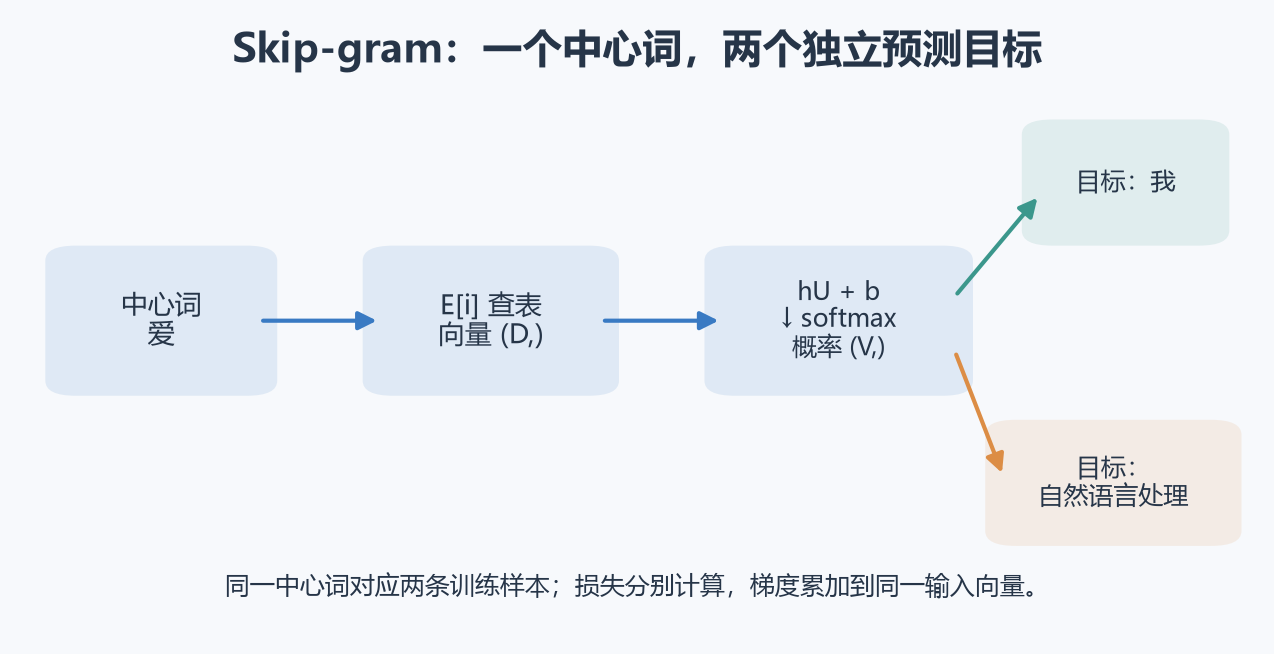

```python
sg_sentences = [
    ["我", "爱", "自然语言处理"],
    ["你", "爱", "人工智能"],
    ["我", "学习", "人工智能"],
]
sg_itos = sorted(set(chain.from_iterable(sg_sentences)))
sg_stoi = {word: i for i, word in enumerate(sg_itos)}

def make_skipgram_pairs(sentences, radius=1):
    if radius < 1:
        raise ValueError("radius至少为1")
    inputs, targets = [], []
    for words in sentences:
        # 为便于与01比较，仅选择拥有完整左右窗口的中心位置。
        for center in range(radius, len(words) - radius):
            for position in range(center - radius, center + radius + 1):
                if position != center:
                    inputs.append(sg_stoi[words[center]])
                    targets.append(sg_stoi[words[position]])
    return np.array(inputs, dtype=np.int64), np.array(targets, dtype=np.int64)

sg_x, sg_y = make_skipgram_pairs(sg_sentences)
print([(sg_itos[i], sg_itos[j]) for i, j in zip(sg_x, sg_y)])
assert len(sg_x) == len(sg_y) == 6
assert (sg_itos[sg_x[0]], sg_itos[sg_y[0]]) == ("爱", "我")
```

本例只保留完整窗口，实际工具也可在句子边缘用较少上下文，并可能随机缩小窗口。不要跨独立文档把上一句末尾当成下一句的上下文。


## 3. 一个Skip-gram前向与更新

输入嵌入矩阵E为`(V,D)`，输出权重U为`(D,V)`。中心词i查到`h=E[i]`，得到`z=hU+b`；每个训练对的交叉熵预测上下文类别。

$$p(j\mid i)=\operatorname{softmax}(E[i]U+b)_j,\qquad L=-\frac{1}{N}\sum_{n=1}^{N}\log p(y_n\mid x_n)$$

```python
sg_rng = np.random.default_rng(2026)
sg_V, sg_D = len(sg_itos), 4
sg_E = sg_rng.normal(0, 0.1, (sg_V, sg_D))
sg_U = sg_rng.normal(0, 0.1, (sg_D, sg_V))
sg_b = np.zeros(sg_V)

def skipgram_loss_grads(x, y, E, U, b):
    h = E[x]
    logits = h @ U + b
    shifted = logits - logits.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    probs = np.exp(log_probs)
    loss = -log_probs[np.arange(len(y)), y].mean()
    dz = probs.copy()
    dz[np.arange(len(y)), y] -= 1
    dz /= len(y)
    dE = np.zeros_like(E)
    np.add.at(dE, x, dz @ U.T)
    return float(loss), dE, h.T @ dz, dz.sum(axis=0)

sg_before, sg_dE, sg_dU, sg_db = skipgram_loss_grads(sg_x, sg_y, sg_E, sg_U, sg_b)
sg_new_E, sg_new_U, sg_new_b = (sg_E - 0.1 * sg_dE,
                                sg_U - 0.1 * sg_dU,
                                sg_b - 0.1 * sg_db)
sg_after = skipgram_loss_grads(sg_x, sg_y, sg_new_E, sg_new_U, sg_new_b)[0]
print("one step loss:", round(sg_before, 6), "->", round(sg_after, 6))
assert sg_after < sg_before
assert sg_dE.shape == (sg_V, sg_D)
```

同一中心词对应多个上下文，梯度要累加到同一E行。完整Softmax下U中各类别一般都会收到梯度，并非只更新真实目标的一列。大词表工具通常使用负采样或层次Softmax减少成本；本例只用于核对原理，不评价语义质量。


## 4. FastText：工具与子词表示

FastText支持监督文本分类与无监督词向量训练。本篇使用`train_unsupervised()`，不用酒店评论标签训练分类器。

和只为完整词维护向量的传统Word2Vec相比，FastText还使用**字符n-gram子词**。一个词可由完整词表示与其子词表示共同构成，词表外词也可能通过子词得到向量。

- 字符n-gram：在词内部取字符片段，帮助处理词形、稀有词与未登录词。
- 后面的文本n-gram：在句子token序列中取连续词/字片段，作为文本特征。

两者都叫n-gram，但所处位置与用途不同。能够算出OOV向量不代表这个向量可靠，子词哈希、语料覆盖和语言特点都影响结果。


## 5. 准备FastText小语料：空格分词、UTF-8、句子边界

用手工分好的词编写10条短句，重复80次仅让很小的示例有足够更新步数。重复不增加独立信息，不是数据增强，也不是新语料。

```python
ft_lines = [
    "我 喜欢 干净 舒适 的 房间",
    "房间 很 干净 服务 很 热情",
    "环境 安静 交通 方便",
    "酒店 整洁 房间 舒适 服务 周到",
    "酒店 早餐 丰富 位置 方便",
    "房间 很 脏 服务 很 差",
    "房间 狭窄 环境 吵闹",
    "我 不 喜欢 潮湿 的 房间",
    "酒店 设施 破旧 服务 冷淡",
    "酒店 早餐 单调 位置 偏远",
]
ft_temp = tempfile.TemporaryDirectory(prefix="nlp02-fasttext-")
ft_dir = Path(ft_temp.name)
ft_corpus_path = ft_dir / "toy-corpus.txt"
ft_corpus_path.write_text("\n".join(ft_lines * 80) + "\n", encoding="utf-8")
print("independent lines:", len(ft_lines), "training lines:", 80 * len(ft_lines))
assert ft_corpus_path.read_text(encoding="utf-8").count("\n") == 800
```

FastText按空白切token，不会自动调用jieba。真实中文语料应先确定分词方案，再用空格分隔。课件以维基百科清洗后的`fil9`演示，本篇未读取或下载该数据，参数规模也不相同。


## 6. 训练模型：明确指定模式和关键参数

```python
ft_config = {
    "model": "skipgram", "dim": 16, "ws": 2,
    "epoch": 20, "lr": 0.05, "minCount": 1,
    "minn": 2, "maxn": 4, "bucket": 2000,
    "thread": 1, "t": 0.01, "verbose": 0,
}
ft_model = fasttext.train_unsupervised(str(ft_corpus_path), **ft_config)
ft_words = ft_model.get_words()
ft_clean_vector = ft_model.get_word_vector("干净")
print("dictionary size:", len(ft_words), "dimension:", ft_model.get_dimension())
print("干净 vector shape:", ft_clean_vector.shape)
assert ft_clean_vector.shape == (16,)
assert np.isfinite(ft_clean_vector).all()
```

| 参数 | 含义 | 本例为何这样设置 |
| --- | --- | --- |
| model | skipgram / cbow | 显式使用本日主题 |
| dim | 向量维度 | 16维足够观察API与shape |
| ws | 上下文窗口距离 | 小窗口，观察局部共现 |
| epoch / lr | 训练轮数 / 学习率 | 教学配置，不是通用最优值 |
| minCount | 最低词频 | 设1避免小语料的词被过滤 |
| minn / maxn | 字符子词长度范围 | 启用子词，演示OOV |
| bucket | 子词哈希桶数 | 设2000降低内存，但哈希碰撞更多 |
| thread | 工作线程 | 单线程便于复查，生产按资源调整 |
| t | 高频词下采样阈值 | 小语料提高阈值，减少高频词被过度丢弃 |

`minCount=1`、较小bucket和重复语料都是教学配置。增加dim/epoch不保证质量更好；类别标签均衡也不是词向量训练的必要条件。真实项目应检查领域覆盖、词频尾部、噪声、耗时与下游验证成绩。


## 7. 保存与加载：验证向量一致

```python
ft_model_path = ft_dir / "toy-skipgram.bin"
ft_model.save_model(str(ft_model_path))
ft_loaded = fasttext.load_model(str(ft_model_path))
for word in ["干净", "房间", "干净整洁"]:
    assert np.allclose(ft_model.get_word_vector(word),
                       ft_loaded.get_word_vector(word), atol=1e-6)
print("model roundtrip passed; bytes:", ft_model_path.stat().st_size)
```

`.bin`保存FastText模型及生成子词向量所需信息。只导出词表中的`.vec`向量表，一般不能完整恢复原模型对新OOV词的子词计算。

还应保存语料预处理、分词词典、训练配置、包版本与模型用途。本例把配置保存在`ft_config`，最后会清理临时文件；实际项目应将模型与这些说明保存到受管理的输出目录。


## 8. 查看近邻与OOV：输出可用，不等于语义正确

```python
ft_neighbors = ft_loaded.get_nearest_neighbors("干净", k=5)
ft_oov_word = "干净整洁"
ft_oov_id = ft_loaded.get_word_id(ft_oov_word)
ft_oov_vector = ft_loaded.get_word_vector(ft_oov_word)
ft_subwords, ft_subword_ids = ft_loaded.get_subwords(ft_oov_word)
print("nearest to 干净:", ft_neighbors)
print("OOV ID:", ft_oov_id, "vector norm:", float(np.linalg.norm(ft_oov_vector)))
print("subwords:", ft_subwords[:8])
assert ft_oov_id == -1
assert ft_oov_vector.shape == (16,) and np.isfinite(ft_oov_vector).all()
assert len(ft_subwords) == len(ft_subword_ids) > 0
```

近邻通常按余弦相似度排序，不是词频排序。小语料中“干净”和“脏”可能共现环境接近，因此向量接近；不能凭相似度就认定两者同义或情感相同。

本篇不报告语义泛化成绩。正式评价可查看不同频率的代表词、人为检查近邻、在领域检索或分类任务上验证，并与简单基线比较。不要根据少量漂亮例子断言模型质量。


## 9. Word2Vec与Embedding：训练方法和查表组件

| 概念 | 它是什么 | 是否一定随上下文变化 |
| --- | --- | --- |
| Word2Vec | 用CBOW或Skip-gram预测任务学习词向量的方法 | 通常每词固定向量 |
| FastText词向量 | 可结合字符子词的静态表示 | 同一词串通常固定 |
| nn.Embedding | 模型中的可学习查表层 | 同一ID查同一行 |
| 上下文表示 | 用RNN/Transformer等结合上下文计算的输出 | 可以随上下文变化 |

课件把Embedding参与训练更新称为“动态”。这里要区分**参数随训练更新**和**表示随上下文变化**：普通Embedding即使可训练，单次前向中同一ID仍得到同一向量；Word2Vec/FastText向量也可以作为初值再微调，或者冻结使用。


## 10. 把FastText向量放进PyTorch Embedding

建立独立且固定的词表，排除FastText的句末符号`</s>`。PAD行设为零；UNK行用已知词向量均值初始化，只是本例的明确策略。

```python
embedding_itos = ["<PAD>", "<UNK>"] + sorted(word for word in ft_words if word != "</s>")
embedding_stoi = {word: i for i, word in enumerate(embedding_itos)}
PAD, UNK = 0, 1
weights = torch.zeros(len(embedding_itos), 16, dtype=torch.float32)
for i, word in enumerate(embedding_itos[2:], start=2):
    weights[i] = torch.from_numpy(ft_loaded.get_word_vector(word))
weights[UNK] = weights[2:].mean(dim=0)
frozen_embedding = nn.Embedding.from_pretrained(weights.clone(), freeze=True, padding_idx=PAD)
trainable_embedding = nn.Embedding.from_pretrained(weights.clone(), freeze=False, padding_idx=PAD)

embedding_ids = torch.tensor([
    [embedding_stoi["房间"], embedding_stoi["干净"], PAD],
    [embedding_stoi["干净"], UNK, PAD],
], dtype=torch.long)
embedding_output = trainable_embedding(embedding_ids)
print("IDs:", tuple(embedding_ids.shape), "vectors:", tuple(embedding_output.shape))
assert embedding_output.shape == (2, 3, 16)
assert torch.equal(embedding_output[0, 1], embedding_output[1, 0])
assert torch.equal(embedding_output[0, 2], torch.zeros(16))
assert not frozen_embedding.weight.requires_grad
```

`from_pretrained()`的freeze设定要明确，不能假设加载向量后就一定更新。这个有限词表把未登录词映射到UNK，会丢掉FastText原有的词级OOV子词能力；若要保持该能力，可以在外部直接计算FastText向量，或设计兼容的子词输入。


## 11. 验证更新与冻结；PAD还需要mask

下面的平方和损失仅用于观察参数更新，**不是情感分类训练**。

```python
embedding_before = trainable_embedding.weight.detach().clone()
embedding_optimizer = torch.optim.SGD(trainable_embedding.parameters(), lr=0.01)
embedding_optimizer.zero_grad(set_to_none=True)
demo_embedding_loss = trainable_embedding(embedding_ids).square().sum()
demo_embedding_loss.backward()
assert torch.equal(trainable_embedding.weight.grad[PAD], torch.zeros(16))
embedding_optimizer.step()
assert not torch.equal(trainable_embedding.weight, embedding_before)
assert torch.equal(trainable_embedding.weight[PAD], torch.zeros(16))
assert torch.equal(frozen_embedding.weight, weights)

with torch.no_grad():
    embedded = frozen_embedding(embedding_ids)
    mask = embedding_ids.ne(PAD).unsqueeze(-1)
    pooled = (embedded * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
    assert pooled.shape == (2, 16)
    assert torch.allclose(pooled[0], (weights[embedding_ids[0, 0]]
                                     + weights[embedding_ids[0, 1]]) / 2)
print("freeze, update and masked mean checks passed")
```

`padding_idx`屏蔽Embedding该行通过查表的梯度，本例PAD为零。不等于后续RNN、注意力、平均池化或损失自动忽略PAD。均值若直接除以固定长度，真实词数少的文本会被额外缩小，应按有效token数归一化。


## 12. 余弦相似度：比较方向，处理零向量

$$\operatorname{cos}(u,v)=\frac{u\cdot v}{\lVert u\rVert_2\lVert v\rVert_2}$$

非零向量的余弦在-1到1之间。零向量的数学余弦未定义；本例函数约定返回0，作为显式工程兜底，而非声称零向量具有某种语义相似度。

```python
def cosine_similarity(a, b):
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    return 0.0 if denominator == 0 else float(np.dot(a, b) / denominator)

similarity_words = ["干净", "脏", "舒适", "狭窄", "热情", "冷淡"]
similarity_vectors = np.stack([ft_loaded.get_word_vector(word) for word in similarity_words])
word_cosine_matrix = np.array([
    [cosine_similarity(a, b) for b in similarity_vectors]
    for a in similarity_vectors
])
assert np.allclose(word_cosine_matrix, word_cosine_matrix.T)
assert np.allclose(np.diag(word_cosine_matrix), 1)
assert cosine_similarity(np.zeros(16), similarity_vectors[0]) == 0
print("干净 vs 脏:", round(word_cosine_matrix[0, 1], 4))
```

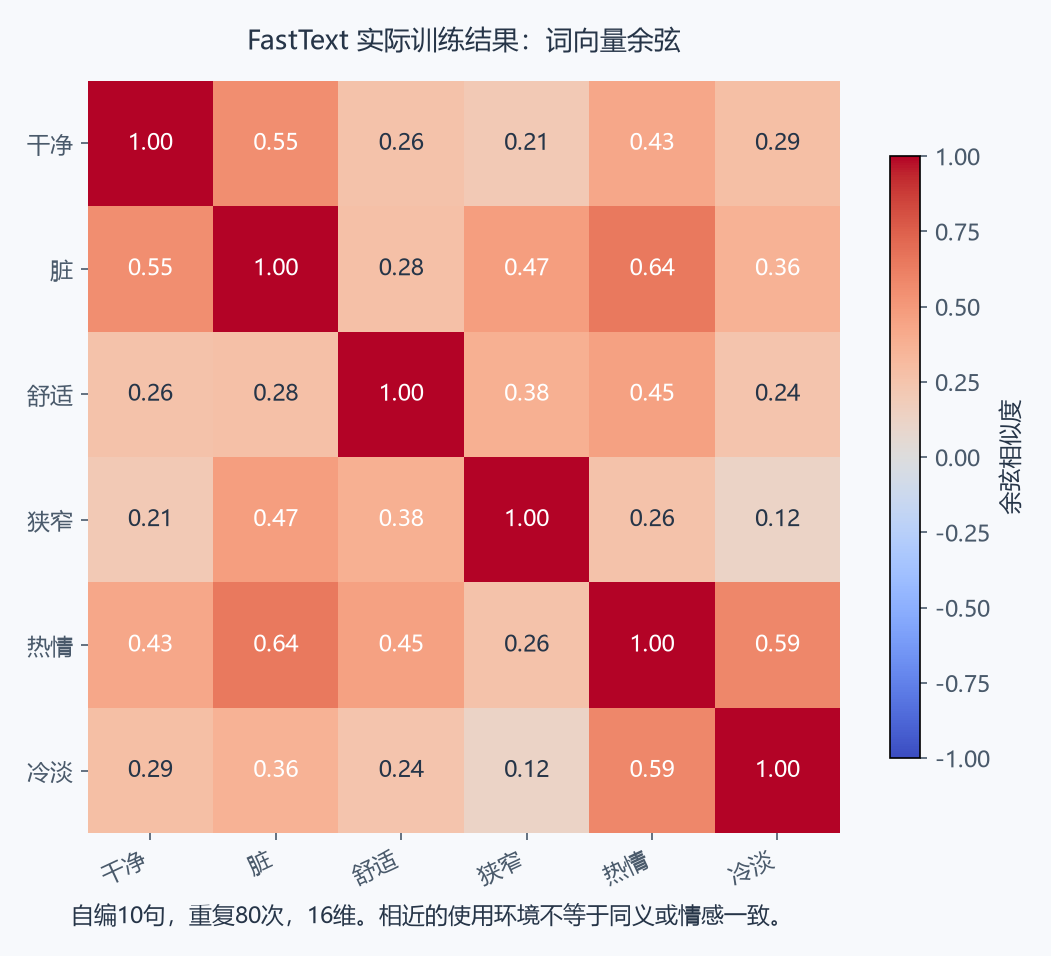

图中向量来自本次实际训练的小模型，不是预训练大模型成绩。相似度反映这些数据和训练目标产生的表示，不等于同义、情感一致或事实一致。


## 13. 自编酒店评论：训练与验证分开检查

沿用课件标签含义：0为消极，1为积极。训练集20条、验证集6条，固定划分用于数据分析，未设置测试集，也未训练评论分类模型。

```python
train_reviews = [
    ("房间干净，床很舒适。", 1), ("服务热情，入住非常方便。", 1),
    ("交通方便，周围环境安静。", 1), ("早餐丰富，房间整洁。", 1),
    ("前台耐心，服务周到。", 1), ("床很舒服，房间明亮。", 1),
    ("环境优美，晚上安静。", 1), ("设施完善，入住方便。", 1),
    ("价格合理，整体满意。", 1), ("房间宽敞，服务热情。", 1),
    ("不是豪华酒店，但干净安静，整体满意。", 1),
    ("入住后房间干净，前台服务热情。" + "交通方便，环境安静，床很舒适。" * 15, 1),
    ("房间很脏，床不舒适。", 0), ("服务冷淡，入住不方便。", 0),
    ("环境吵闹，晚上无法休息。", 0), ("早餐单调，房间潮湿。", 0),
    ("设施破旧，房间狭窄。", 0), ("价格昂贵，整体失望。", 0),
    ("虽然位置方便，但是服务很差。", 0), ("房间不干净，服务也不热情。", 0),
]
dev_reviews = [
    ("房间舒适，服务周到。", 1), ("早餐丰富，交通方便。", 1),
    ("前台热情，提供智能门锁，整体满意。", 1),
    ("房间潮湿，隔音很差。", 0), ("服务冷淡，价格昂贵。", 0),
    ("环境吵闹，设施破旧。", 0),
]
train_df = pd.DataFrame(train_reviews, columns=["sentence", "label"])
dev_df = pd.DataFrame(dev_reviews, columns=["sentence", "label"])
for frame in [train_df, dev_df]:
    assert frame["sentence"].map(lambda x: isinstance(x, str) and bool(x.strip())).all()
    assert frame["label"].isin([0, 1]).all()
    assert not frame["sentence"].duplicated().any()
assert set(train_df["sentence"]).isdisjoint(dev_df["sentence"])
print("train/dev sizes:", len(train_df), len(dev_df))
```

本例特意保留一条长评论以演示异常检查，也保留带“不”“但是”的句子。真实数据还应检查缺失、编码、重复评论、同酒店/同用户分组、标签冲突和标注标准，不要把清洗规则当作自动判断正确标签的方法。


## 14. 标签分布：不要求所有数据都变成1:1

```python
train_label_counts = train_df["label"].value_counts().reindex([0, 1], fill_value=0)
dev_label_counts = dev_df["label"].value_counts().reindex([0, 1], fill_value=0)
print("train counts:", train_label_counts.to_dict())
print("dev counts:", dev_label_counts.to_dict())
majority_baseline = float(train_label_counts.max() / len(train_df))
print("train majority-class baseline accuracy:", majority_baseline)
```

多数类全预测的准确率是一个简单基线。本例训练集积极12条、消极8条，基线60%，这不是任何已训练模型的成绩。

课件建议调整正负比例，本篇补充：**不存在所有分类任务都必须1:1的规则**。训练时可依据业务成本使用加权损失、采样或补充少数类数据；验证/测试应保留与目标场景相符的分布，并看macro F1、各类recall等。随意删掉多数类会丢失信息；过采样不能跨划分复制样本。


## 15. map：惰性转换与句长定义

`map()`把函数应用到可迭代对象的每个元素，返回惰性迭代器，消费后需要重新创建。赋给DataFrame列时本例先转成列表。

```python
length_iterator = map(len, ["房间干净", "服务很热情"])
assert list(length_iterator) == [4, 5]
assert list(length_iterator) == []

def review_tokens(text):
    return [word for word in tokenizer.lcut(text, HMM=False)
            if word.strip() and not all(not char.isalnum() for char in word)]

for frame in [train_df, dev_df]:
    frame["char_length"] = list(map(len, frame["sentence"]))
    frame["tokens"] = list(map(review_tokens, frame["sentence"]))
    frame["token_length"] = frame["tokens"].map(len)
print(train_df[["char_length", "token_length"]].describe())
```

`len(text)`是Python字符数，不是UTF-8字节数，也不是分词后的token数。本例字符长度包含标点，token长度排除了空白和纯标点。若模型用子词tokenizer，应统计它的token长度，并考虑特殊token占用；不能直接用字符分位数确定模型最大token长度。


## 16. 长度分布和按标签散点：找到需要人工检查的样本

```python
length_summary = {
    "train_char_p50": float(train_df["char_length"].quantile(0.5)),
    "train_char_p95": float(train_df["char_length"].quantile(0.95)),
    "train_token_p95": float(train_df["token_length"].quantile(0.95)),
}
longest_index = int(train_df["char_length"].idxmax())
print("summary:", length_summary)
print("longest:", train_df.loc[longest_index, ["label", "char_length", "token_length"]].to_dict())
print("longest preview:", train_df.loc[longest_index, "sentence"][:100])
```

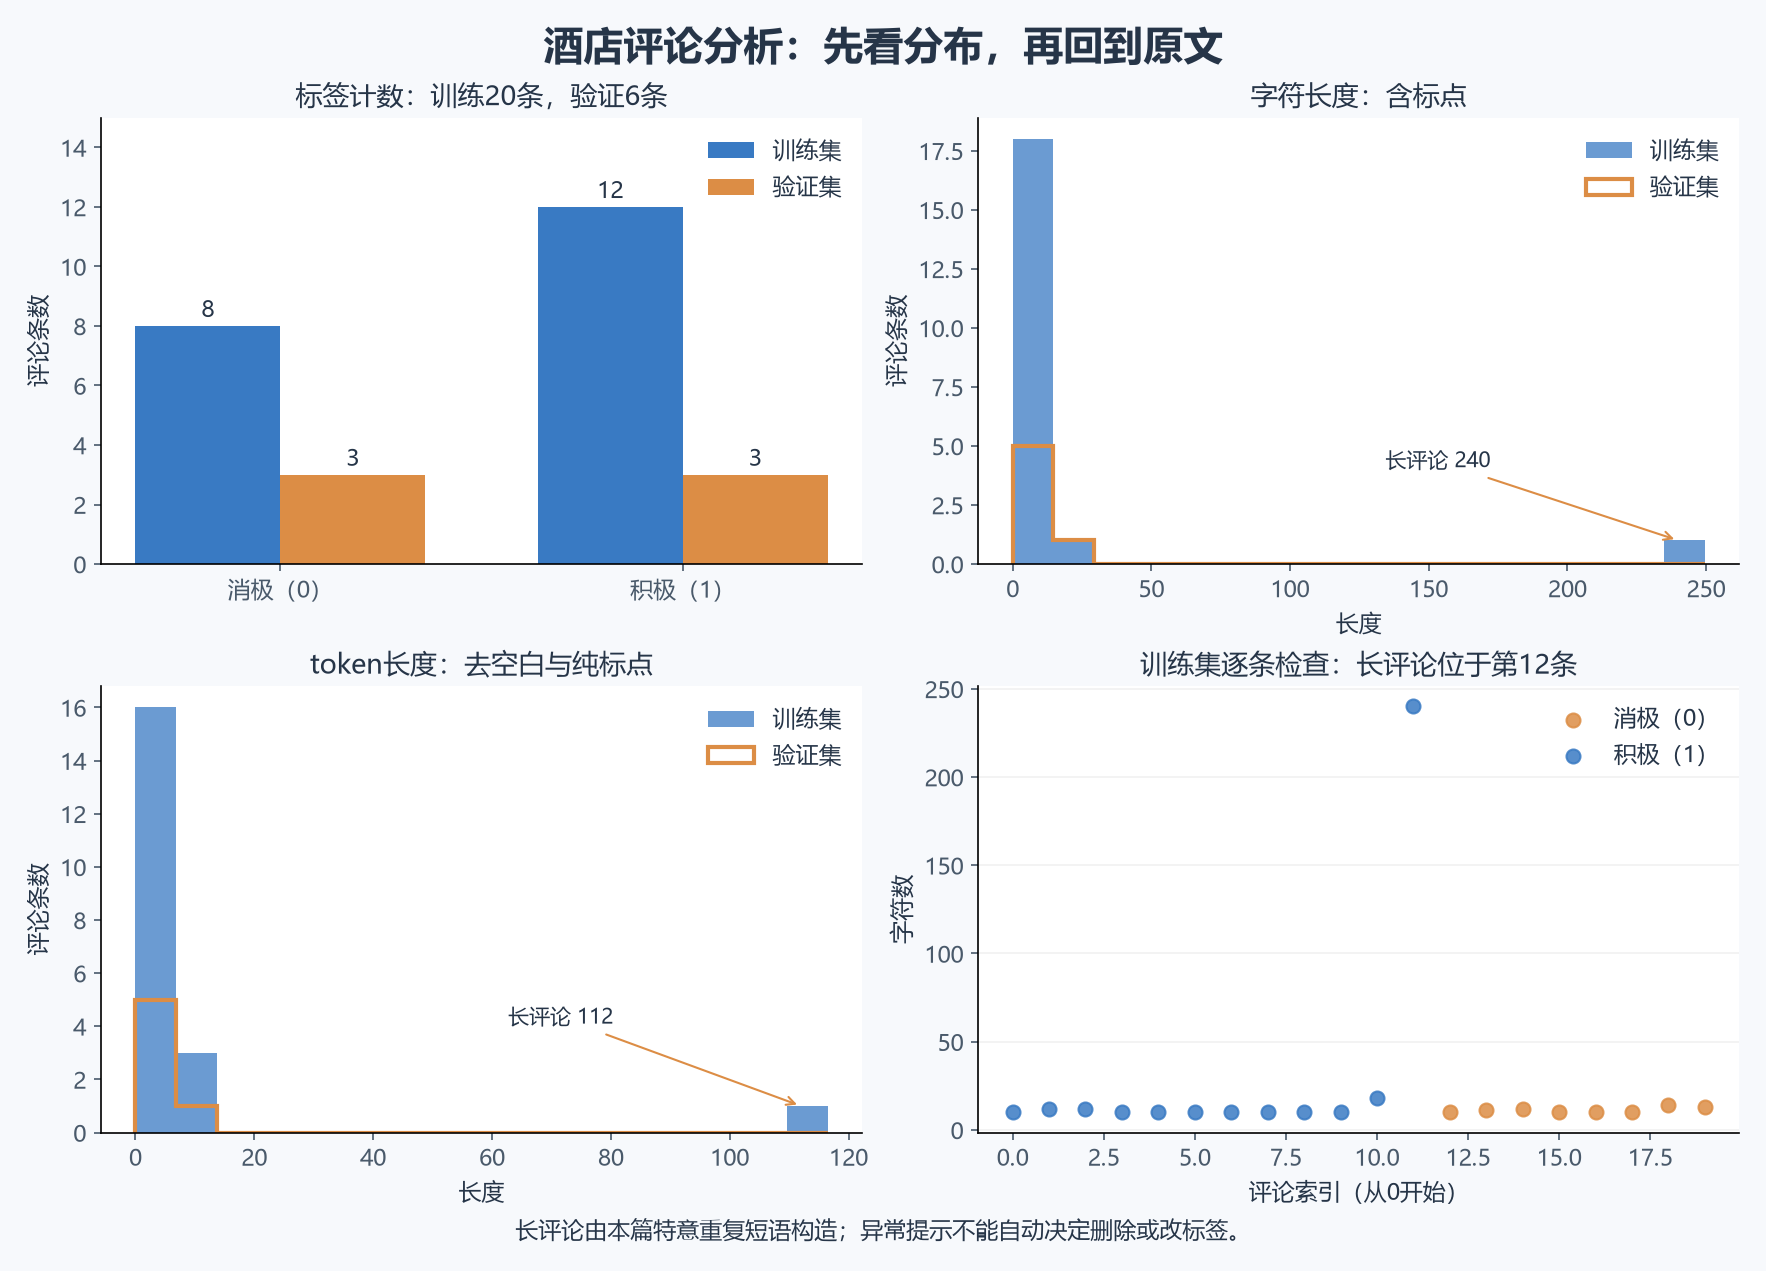

散点只用于把异常样本定位到原文。本例长评论是人为重复短语，应标记为需审查，不因它长就自动改标签或删除。真实长文本也可能完全合法。

长度截断应在训练集分布、任务信息位置、硬件成本和验证效果之间做选择。p95只是统计提示；截掉末尾“不推荐”可能改变情感，不能只追求覆盖率。截断/填充的完整数据集处理放到后续主题。


## 17. chain、Counter：token数、词表数和文档频次

`chain.from_iterable(rows)`把一层嵌套序列展开。`chain(rows)`则逐个返回原来的子列表。如果rows是字符串，展开的是字符而非已分好的词。

```python
toy_rows = [["房间", "干净"], ["服务", "热情"]]
assert list(chain.from_iterable(toy_rows)) == ["房间", "干净", "服务", "热情"]
assert list(chain(toy_rows)) == toy_rows

train_word_counts = Counter(chain.from_iterable(train_df["tokens"]))
train_document_counts = Counter(chain.from_iterable(set(row) for row in train_df["tokens"]))
train_vocabulary = set(train_word_counts)
dev_flat_tokens = list(chain.from_iterable(dev_df["tokens"]))
dev_unknown_count = sum(word not in train_vocabulary for word in dev_flat_tokens)
dev_unknown_rate = dev_unknown_count / len(dev_flat_tokens)
print("train total tokens:", sum(train_word_counts.values()))
print("train unique tokens:", len(train_vocabulary))
print("top frequency:", train_word_counts.most_common(8))
print("dev OOV count/rate:", dev_unknown_count, round(dev_unknown_rate, 4))
assert all(train_document_counts[word] <= train_word_counts[word] for word in train_vocabulary)
```

- token总数：所有出现次数相加。
- 不同词汇数：去重后的词表大小。
- 词频TF：一个词总共出现几次。
- 文档频次DF：多少条文档包含它，每条只计一次。

长评论重复短语会抬高TF，DF更容易提示这是少数文档的集中重复。开发集OOV用于观察覆盖；不要为了降低OOV而把开发集词加入训练词表。这里的OOV是酒店评论训练词表口径，与前面的FastText子词OOV能力不是同一个概念。


## 18. 高频形容词：保留频次，也回看上下文

```python
pos_tokenizer = pseg.POSTokenizer(tokenizer)

def adjective_words(text):
    return [pair.word for pair in pos_tokenizer.cut(text, HMM=False)
            if pair.flag.startswith("a")]

adjective_counts = {}
for label in [0, 1]:
    subset = train_df.loc[train_df["label"] == label, "sentence"]
    adjective_counts[label] = Counter(chain.from_iterable(map(adjective_words, subset)))
    print("label:", label, "adjectives:", adjective_counts[label].most_common())
assert adjective_counts[0] and adjective_counts[1]
```

课件示例筛选`flag == 'a'`；本文采用`startswith('a')`，也包含ad/an等以a开头的标签，这是本篇的明确分析口径。工具词性仍可能错误，应检查代表句子。

“不干净”中的“干净”也可能进入消极词云，“不是豪华酒店，但整体满意”会在积极数据中出现“豪华”。仅保留形容词丢掉了否定与转折，不能根据某词出现在哪张词云就自动改评论标签。


## 19. 词云：用已有Counter生成，避免再次分词

```python
from wordcloud import WordCloud
from matplotlib import font_manager

# 优先找到当前系统的中文字体；其他系统可改成已安装字体的绝对路径。
font_candidates = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "PingFang SC"]
chinese_font_path = None
for family in font_candidates:
    try:
        chinese_font_path = font_manager.findfont(family, fallback_to_default=False)
        break
    except ValueError:
        continue
if chinese_font_path is None:
    raise RuntimeError("请为词云指定系统中的中文字体文件")

adjective_clouds = {}
for label in [0, 1]:
    adjective_clouds[label] = WordCloud(
        font_path=chinese_font_path, width=900, height=440,
        background_color="white", max_words=60, random_state=2026,
        collocations=False,
    ).generate_from_frequencies(adjective_counts[label])
print("wordcloud generated from explicit frequencies")
```

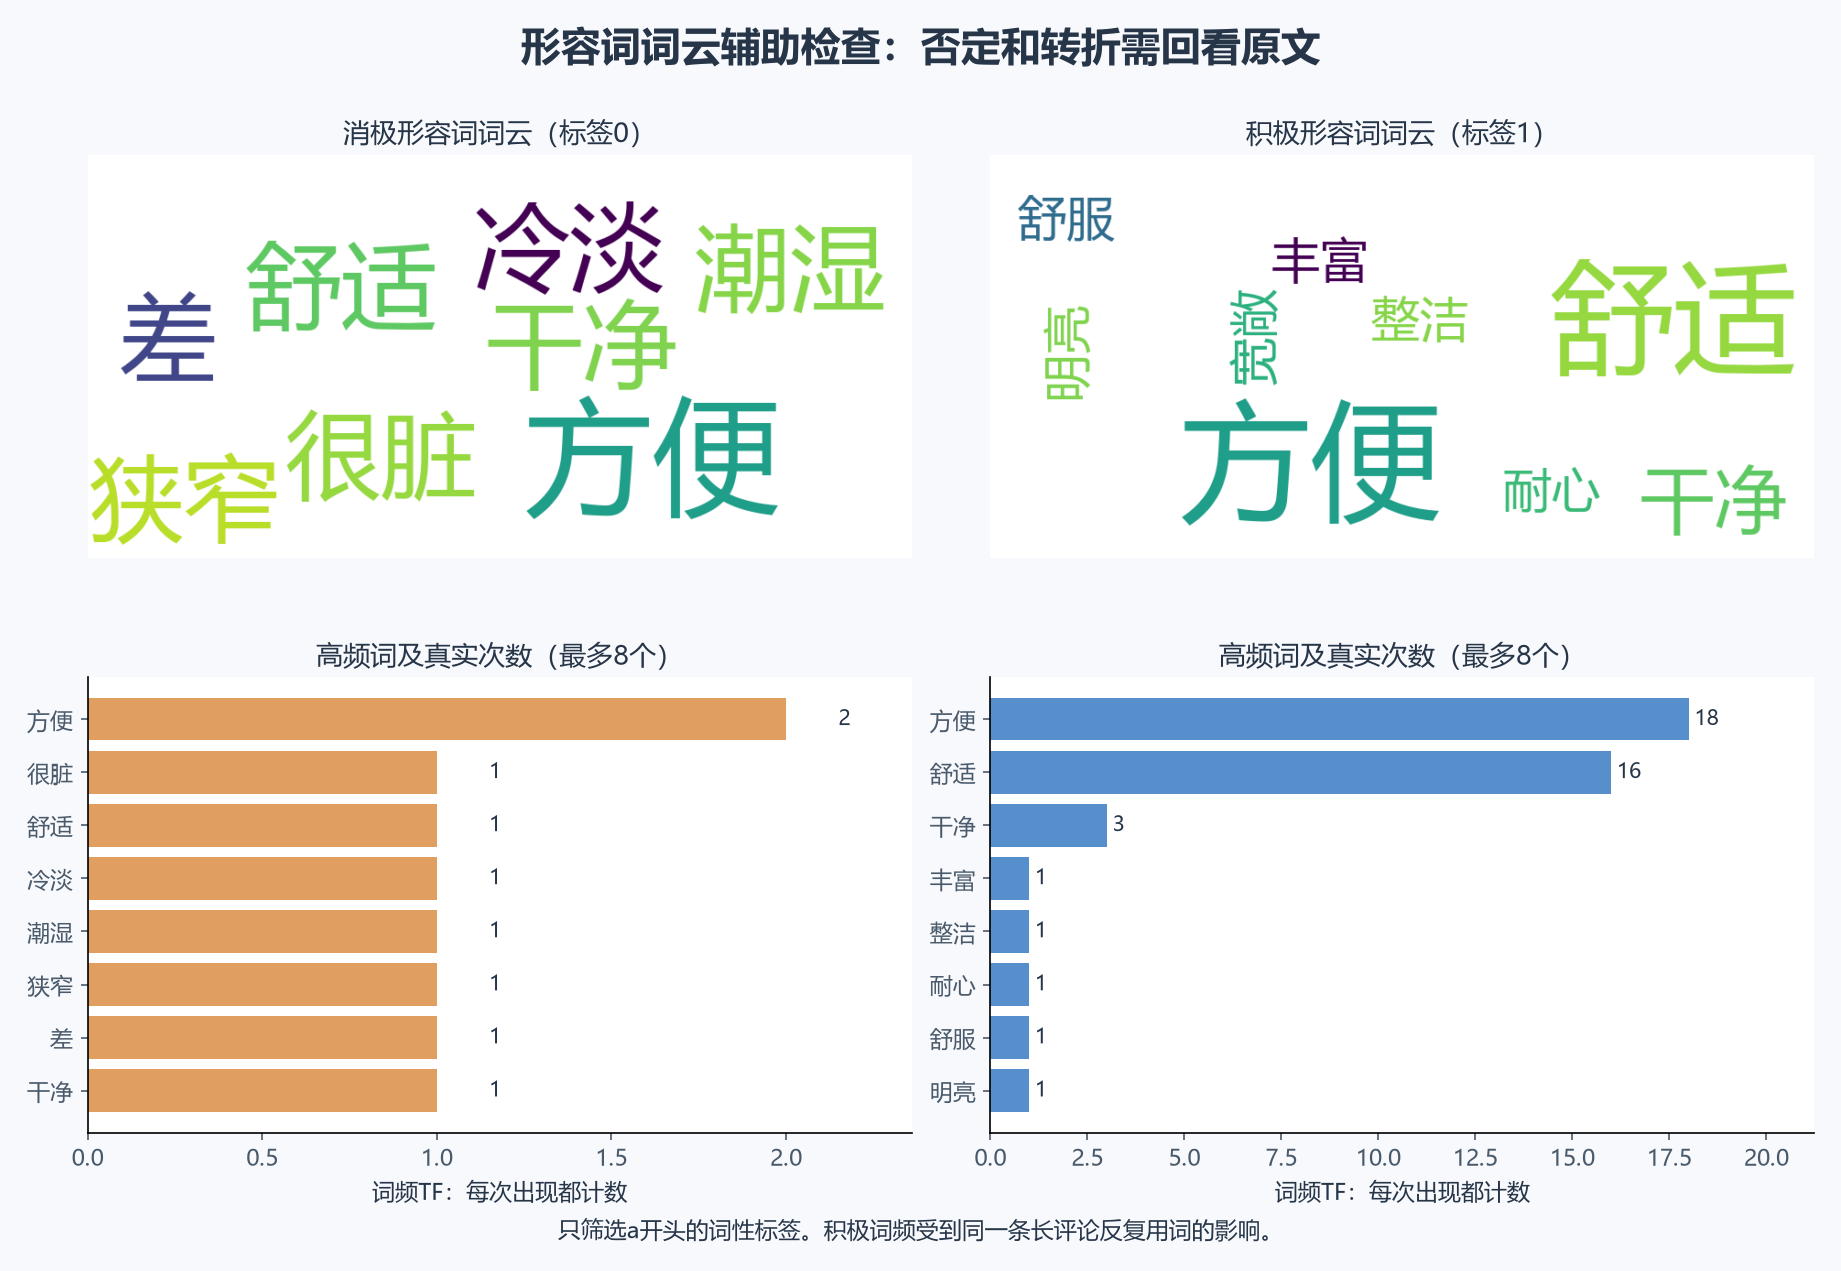

`generate_from_frequencies()`直接使用分词统计好的权重，避免再次用默认文本正则切词。词云字体大小不提供精准数值比较，所以图中同时列出频次；样本量和文档长短不同也会影响视觉大小。

随机种子只固定布局。词云用于发现线索与辅助人工审查，不是情感模型或因果分析。这里的大量“方便”“舒适”部分来自同一条长评论重复，应结合DF和原文理解。


## 20. zip与n-gram：保留相邻位置、区分次数与集合

`zip()`默认在最短输入结束时停止；这正适合把偏移的序列配对成相邻窗口。需要强制等长时可用`strict=True`。

```python
assert list(zip([1, 2, 3], ["a", "b"])) == [(1, "a"), (2, "b")]

def ngrams(tokens, n):
    if not isinstance(n, int) or n < 1:
        raise ValueError("n必须是正整数")
    if len(tokens) < n:
        return []
    return list(zip(*(tokens[offset:] for offset in range(n))))

gram_tokens = ["房间", "不", "干净", "服务", "不", "热情"]
gram_bigrams = ngrams(gram_tokens, 2)
gram_trigrams = ngrams(gram_tokens, 3)
print("bigrams:", gram_bigrams)
print("trigrams:", gram_trigrams)
assert len(gram_bigrams) == len(gram_tokens) - 1
assert ngrams(["不", "干净", "不", "干净"], 2).count(("不", "干净")) == 2
```

n-gram是连续n个token的特征。“不 / 干净”作为bigram可保留一部分局部否定关系，但不能解决所有远距离转折与情感逻辑。`set(ngrams(...))`统计不同特征，`Counter(ngrams(...))`统计出现次数，两者含义不同。

每条文本分别生成窗口，不能先把所有评论展平再取n-gram，否则会出现跨评论的虚假组合。


## 21. 建立n-gram特征ID：只在训练集拟合

课件把bigram映射为新ID并附加到词ID列表。本文给出无冲突的稳定编号：特殊token与unigram在前，新bigram从原词表大小开始。

```python
feature_itos = ["<PAD>", "<UNK>"] + sorted(train_vocabulary)
feature_stoi = {word: i for i, word in enumerate(feature_itos)}
training_bigram_set = set(chain.from_iterable(ngrams(row, 2) for row in train_df["tokens"]))
bigram_to_id = {gram: len(feature_itos) + i
                for i, gram in enumerate(sorted(training_bigram_set))}

def add_bigram_features(tokens):
    base_ids = [feature_stoi.get(word, 1) for word in tokens]
    extra_ids = [bigram_to_id[gram] for gram in ngrams(tokens, 2)
                 if gram in bigram_to_id]
    return base_ids + extra_ids

first_feature_ids = add_bigram_features(train_df.iloc[0]["tokens"])
assert set(feature_stoi.values()).isdisjoint(bigram_to_id.values())
assert min(bigram_to_id.values()) == len(feature_itos)
print("unigram vocabulary:", len(feature_itos), "bigram vocabulary:", len(bigram_to_id))
print("first feature list:", first_feature_ids)
```

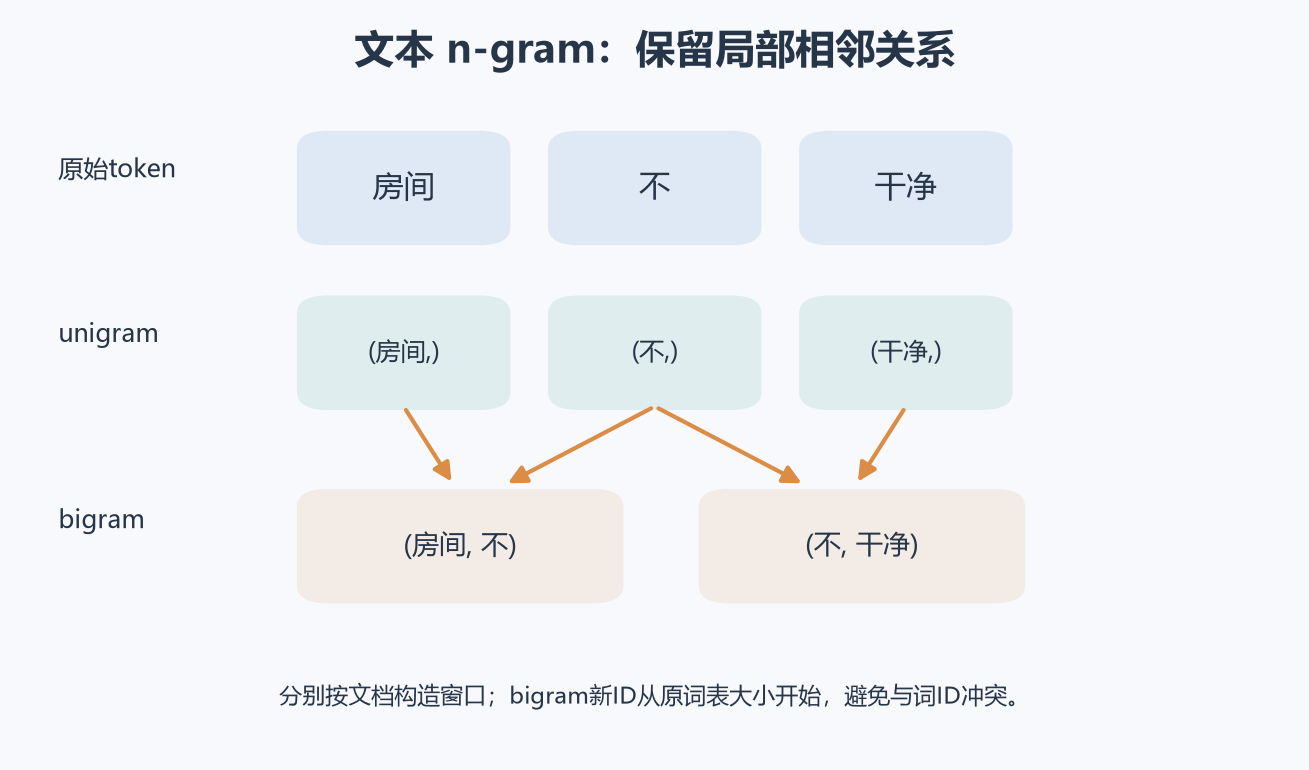

重复bigram在上面的列表中保留重复出现，便于计数或特征袋；未知bigram按本例策略忽略。保存模型时要一起保存两个映射和处理策略，不能用临时Python哈希值当作稳定ID。

把词ID与bigram ID直接附加成一个列表适合某些特征袋模型；它已经不再是普通原文token的时间顺序，不应无条件送给RNN或Transformer当自然语言序列。TF-IDF等模型通常直接在自己的特征空间中编码n-gram。


## 22. 文本相似度一：Jaccard集合重叠

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

```python
def jaccard_similarity(tokens_a, tokens_b):
    a, b = set(tokens_a), set(tokens_b)
    union = a | b
    return 0.0 if not union else len(a & b) / len(union)

assert np.isclose(jaccard_similarity(["房间", "干净"], ["房间", "舒适"]), 1/3)
assert jaccard_similarity([], []) == 0.0  # 本例约定空文本不产生相似证据
assert jaccard_similarity(["好", "好"], ["好"]) == 1.0
```

Jaccard忽略次数和词序，适合观察词集合重叠，不能保证语义一致。空集合的比值是0/0，本文显式约定返回0；其他系统可能约定两个空集合为1，比较时要统一规则。


## 23. 文本相似度二：词频余弦与n-gram

使用Counter构造共同特征空间里的词频向量，计算余弦。它考虑次数，但unigram仍忽略顺序。下面用“我喜欢你”和“你喜欢我”观察这个限制。

```python
def counter_cosine(counter_a, counter_b):
    keys = sorted(set(counter_a) | set(counter_b))
    a = np.array([counter_a[key] for key in keys], dtype=np.float64)
    b = np.array([counter_b[key] for key in keys], dtype=np.float64)
    return cosine_similarity(a, b)

comparison_tokens = [
    ["我", "喜欢", "你"], ["你", "喜欢", "我"],
    ["我", "不", "喜欢", "你"], ["房间", "很", "干净"],
]
unigram_counters = [Counter(row) for row in comparison_tokens]
mixed_counters = [Counter([(word,) for word in row] + ngrams(row, 2))
                  for row in comparison_tokens]
text_unigram_matrix = np.array([
    [counter_cosine(a, b) for b in unigram_counters] for a in unigram_counters
])
text_mixed_matrix = np.array([
    [counter_cosine(a, b) for b in mixed_counters] for a in mixed_counters
])
assert np.isclose(text_unigram_matrix[0, 1], 1.0)
assert text_mixed_matrix[0, 1] < text_unigram_matrix[0, 1]
print("reversed roles: unigram:", text_unigram_matrix[0, 1],
      "unigram+bigram:", text_mixed_matrix[0, 1])
```

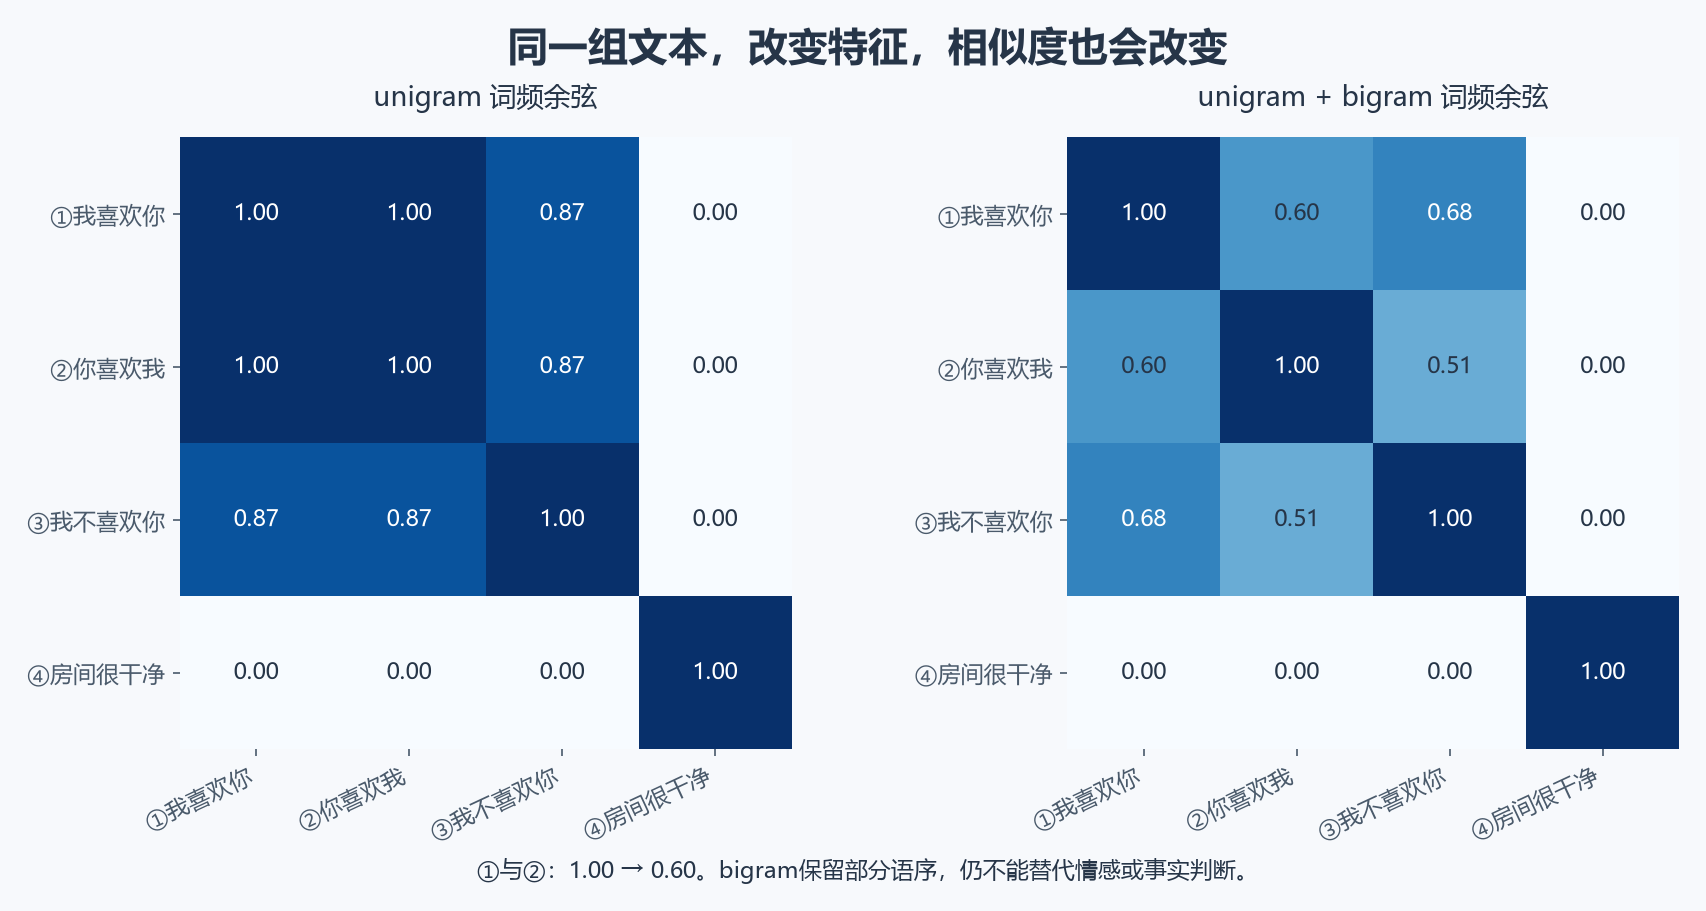

新增bigram保留部分局部顺序，但相似度仍不是蕴含、情感或事实等价。否定只增加少量特征时，分数仍可能很高。TF-IDF可以减弱常见词权重；平均词向量或句向量可以提供另一种表示，但仍应按具体任务验证阈值。

同时报告“文本单位、分词规则、向量方法、相似度公式”才方便复查。不能把词向量余弦、词集合Jaccard和文档词频余弦的数值混为一个统一评分。


## 24. 清理示例文件与保存配置

```python
analysis_config = {
    "segmentation": {"tool": "jieba", "version": jieba.__version__, "HMM": False},
    "token_filter": "remove whitespace and tokens containing only punctuation",
    "label_meaning": {"0": "negative", "1": "positive"},
    "adjective_rule": "POS tag starts with a",
    "fasttext": ft_config,
    "feature_itos": feature_itos,
    "bigram_mapping": [[list(gram), index] for gram, index in sorted(bigram_to_id.items())],
}
config_json = json.dumps(analysis_config, ensure_ascii=False)
restored_config = json.loads(config_json)
restored_bigram_mapping = {tuple(gram): index for gram, index in restored_config["bigram_mapping"]}
assert restored_bigram_mapping == bigram_to_id
ft_temp.cleanup()
assert not ft_dir.exists()
print("configuration roundtrip and temporary file cleanup passed")
```

模型已读入内存，清理训练用的临时文件不影响当前会话的查询；重启后则需要真正保存的`.bin`模型才能恢复。因此这里清理只用于教学运行，不代表实际项目无需持久保存权重。


## 25. 实跑记录

本次使用Python 3.12.13、NumPy 1.26.4、fasttext-wheel 0.9.2、PyTorch 2.14.1+cpu、jieba 0.42.1。按顺序执行了**22段Python示例**，全部通过；手写Skip-gram梯度另经数值差分核对。以下是自编语料的实际输出，不是课程原实验或泛化成绩。

| 检查 | 本次结果 |
| --- | --- |
| Skip-gram样本对 | 6对，重复中心词的梯度正确累加 |
| 一步更新损失 | 1.789899 → 1.778437 |
| 梯度差分最大绝对误差 | 3.40e-11 |
| FastText训练 | 10句×80次=800行；词表31项（含句末符），向量16维 |
| 模型保存/加载 | 三个词向量核对一致；bin文件132,570字节 |
| OOV“干净整洁” | 词ID为-1；16维有限向量，范数1.4269 |
| Embedding | 输入(2,3)→输出(2,3,16)；冻结、更新、PAD与masked mean检查通过 |
| 酒店评论标签 | 训练消极8/积极12；验证各3；多数类基线60% |
| 训练评论词汇 | token总数199；去重词表51 |
| 验证集词表外词 | 4次，占15.38%；未加入训练词表 |
| 人为长评论 | 字符240，token 112，已标记供人工检查 |
| 训练bigram特征 | 74个；ID无冲突，配置JSON可恢复 |
| “我喜欢你”/“你喜欢我” | unigram余弦1.00；加入bigram后0.60 |
| 交付图片 | 6张PNG，均存入Notebook attachments；无外部图片依赖 |

本次小模型对“干净”的5个近邻：

| 近邻词 | 余弦相似度 |
| --- | --- |
| 不 | 0.5843 |
| 脏 | 0.5489 |
| 潮湿 | 0.4884 |
| 我 | 0.4866 |
| 热情 | 0.4270 |

近邻只是复查训练与API的实际输出。小语料中的共现会让反义词或功能词也很接近，不能据此声称模型理解情感。分词、依赖版本、语料或FastText训练环境改变时，词频与近邻可能变化。这里没有训练评论分类器、独立测试集或语义泛化评分。


## 26. 常见问题与排查

| 问题 | 检查方向 |
| --- | --- |
| FastText安装失败 | Python版本、系统和编译依赖；用兼容的独立环境 |
| 训练报Empty vocabulary | 输入为空、没正确空格分词、minCount过滤了小语料 |
| 训练遇到NaN | 包/二进制兼容性、学习率、语料与数值；先跑最小例子 |
| 中文被当作一个长词 | FastText不会自动jieba分词，输入要按既定规则预分词 |
| 向量维度和Embedding不符 | 核对dim、词表顺序、预训练矩阵的(V,D) |
| 载入后PAD变成普通词 | 特殊token ID与映射发生错位 |
| Embedding未更新 | freeze设定、梯度、优化器是否包含该参数 |
| 称Embedding“动态”就以为词义随句子变化 | 参数更新与上下文表示是不同概念 |
| 标签比例不均就直接删样本 | 先看业务分布、代价、指标和可靠划分 |
| 字符p95当成token最大长度 | 字符、词、子词长度口径不同 |
| chain结果是字符或子列表 | 输入是否分词，是否正确使用from_iterable |
| 词云中文是方框 | 中文字体路径与字体覆盖 |
| 消极词云里出现“干净”就改标签 | 回看“不干净”等否定和转折上下文 |
| n-gram ID与词ID冲突 | 从词表大小开始稳定分配新ID，保存映射 |
| 相似度很高但意义不同 | unigram忽略顺序，否定和角色反转仍可能得高分 |

先检查文本→token→ID→向量和统计口径，再调整模型。高频、近邻、相似度都是分析信号，不是自动正确性证明。


## 27. 练习与参考答案

1. CBOW和Skip-gram的预测方向有什么区别？
2. 完整Softmax下，输出权重只更新目标词对应列吗？
3. FastText能给未登录词生成向量，是否证明它理解这个词？导出vec能否完整替代bin？
4. `nn.Embedding(1000,64)`接收`(8,20)`整数ID，输出shape和参数量是多少？
5. 同一个词在两个句子里经过普通Embedding，是否自动得到不同向量？
6. 分类训练集60%积极、40%消极，必须删除积极样本变成1:1吗？
7. 长评论中重复20次“房间”，TF和DF分别增加多少？
8. 长度T=6的序列有几个bigram位置、几个trigram位置？去重后一定仍有那么多吗？
9. “我喜欢你”和“你喜欢我”词频余弦为什么等于1？
10. 为什么消极词云里出现“热情”不能自动判定标签错误？

参考答案：

- 第1题：CBOW上下文预测中心词；Skip-gram中心词预测上下文词。
- 第2题：通常不是。非目标类别也通过Softmax概率贡献梯度。
- 第3题：子词可构造向量，但质量要验证；一般vec不包含完整子词参数，不能完整替代bin。
- 第4题：输出`(8,20,64)`，参数量64000。
- 第5题：不会，同一ID查同一行；后续上下文网络的输出可以不同。
- 第6题：不必须；依据任务和数据选择损失、采样与评价，验证/测试保持可信分布。
- 第7题：该文档给TF贡献20次，给DF贡献1篇；若还有其他出现则另计。
- 第8题：5和4；去重后可能更少。
- 第9题：unigram计数完全相同，忽略语序与主宾语角色。
- 第10题：可能是“不热情”或转折句，必须检查原文。

实践：对长评论比较TF与DF；在训练集上构造bigram映射并测试未知组合；用不同FastText dim/epoch检查近邻变化，同时记录相同语料与预算；加入否定、反义和角色反转例子检查相似度局限。


## 28. 速查与day02来源对照

| 概念/API | 关键约定 |
| --- | --- |
| Skip-gram | 一个中心词 → 多个上下文预测对 |
| FastText输入 | UTF-8，预先按规则用空格分词 |
| train_unsupervised | 显式model、dim、ws、minCount和子词参数 |
| save_model / load_model | bin模型保存与加载，核对向量一致 |
| get_word_vector | D维向量，OOV可经子词计算 |
| get_nearest_neighbors | 近邻检查不是最终质量评分 |
| Embedding | 权重(V,D)，输入(B,T)，输出(B,T,D) |
| from_pretrained | 明确freeze和padding_idx |
| map / chain / zip | 逐项转换 / 展平一层 / 对应位置配对，通常是惰性迭代 |
| TF / DF / 词表大小 | 出现次数 / 文档数 / 不同token数 |
| n-gram | 单文档连续n个token，训练集建映射 |
| Jaccard / cosine | 集合交并比 / 向量方向，口径需说明 |

已核对的18个day02视频标题（省略`.mp4`）：

| 序号 | 标题 |
| --- | --- |
| 01 | Word2Vec之SkipGram词向量解释(理解) |
| 02 | FastText_环境搭建(掌握) |
| 03 | FastText_词向量模型的训练和保存(掌握) |
| 04 | FastText_加载_查看_模型效果检验(掌握) |
| 05 | FastText_模型参数设定(掌握) |
| 06 | WordEmbedding和Word2Vec的区别(理解) |
| 07 | WordEmbedding_获取词向量(掌握) |
| 08 | WordEmbedding_查看词向量的相似性(了解) |
| 09 | 文本分析_标签数据分布查看(理解) |
| 10 | 扩展_map()函数功能介绍(理解) |
| 11 | 文本分析_句子长度分布分析(理解) |
| 12 | 文本分析_正负样本长度散点分布(理解) |
| 13 | 扩展_chain()函数介绍(理解) |
| 14 | 文本分析_词汇统计(掌握) |
| 15 | 文本分析_高频形容词词云(掌握) |
| 16 | 扩展_zip()函数用法解释(理解) |
| 17 | 文本特征处理_n-gram代码演示(掌握) |
| 18 | 扩展_如何计算两个文本的相似度(理解) |

**资料范围：**网页预览读取《02-文本预处理-上》第36–46页与《03-文本预处理-下》第4–30页的相关正文，未取得本地PDF；第二份课件后续的长度规范和回译不在本篇展开。视频未逐段转录，课程原代码及酒店/维基百科原数据正文未取得。全部语料、代码、训练参数和6张图为独立教学示例，不是课程原实验成绩。

可查阅：[FastText官方教程](https://fasttext.cc/docs/en/unsupervised-tutorial.html)、[Python API](https://fasttext.cc/docs/en/python-module.html)、[PyTorch Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html)、[WordCloud频次API](https://amueller.github.io/word_cloud/generated/wordcloud.WordCloud.html)、[Python itertools](https://docs.python.org/3/library/itertools.html)。
